In [38]:
from typing import TypedDict


class State(TypedDict):
    """State of the application."""

    # The current state of the application.
    graph_state: str

In [39]:
#### NODES

def start_play(state:State):
    print("""Start the play. """)
    return {"graph_state": state["graph_state"] + "I want to play "}

def Snooker(state:State):
    print("Snooker Node has been called.")
    return {"graph_state": state["graph_state"] + "Snooker "}

def Cricket(state:State):
    print("Cricket Node has been called.")
    return {"graph_state": state["graph_state"] + "Cricket "}




In [40]:
import random
from typing import Literal


def Random_play(state:State) -> Literal["Snooker","Cricket"]:
    """Randomly choose between Snooker and Cricket."""
    choice = random.choice(["Snooker", "Cricket"])
    print(f"Randomly chosen: {choice}")
    return choice



In [41]:
from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END


In [42]:
### Building Graph

graph = StateGraph(State)

graph.add_node("start_play", start_play)
graph.add_node("Snooker", Snooker)
graph.add_node("Cricket", Cricket)


graph.add_edge(START,"start_play")
graph.add_conditional_edges("start_play", Random_play)
graph.add_edge("Snooker", END)
graph.add_edge("Cricket", END)



In [43]:
### Compile Graph

graph.compile()

KeyboardInterrupt: 

### For Trip Mate

plan Trip -> list 5 best places to visit.
plan flights -> finds the best 3 of cheaapest and best 3 of fastest flight.
plan hotels -> finds the top 10 hotels.


In [ ]:
from ollama import chat

In [ ]:
import os
from dotenv import load_dotenv
from langchain_ollama import ChatOllama

load_dotenv("/Users/omkar/Documents/supplychain/.env", override=True)

def oracle_llm(model: str, **kwargs) -> ChatOllama:
    return ChatOllama(
        model=model,
        base_url=os.getenv("OLLAMA_BASE_URL"),
        client_kwargs={
            "headers": {"Authorization": f"Bearer {os.getenv('OLLAMA_API_KEY')}"},
            "timeout": 600,
        },
        **kwargs,
    )

extract_llm = oracle_llm("qwen2.5:1.5b", temperature=0)
llm = oracle_llm("llama3.2", num_predict=600)

# quick connection test
print(os.getenv("OLLAMA_BASE_URL"))
print(extract_llm.invoke("Reply with one word: hello").content)

https://193-123-179-35.sslip.io
Hello!


In [ ]:
#### flight Seach Functionalituy


import os, requests
from dotenv import load_dotenv
load_dotenv(override=True)

BASE = "https://api.oag.com"
KEYS = {
    "flight":     os.getenv("OAG_FLIGHTS_KEY"),
    "schedules":   os.getenv("OAG_SCHEDULES_KEY"),
    "master-data": os.getenv("OAG_MASTERDATA_KEY"),
}

for service, key in KEYS.items():
    r = requests.get(f"{BASE}/{service}/health",
                     headers={"Ocp-Apim-Subscription-Key": key}, timeout=20)
    print(service, r.status_code, r.text)

flight 404 { "statusCode": 404, "message": "Resource not found" }
schedules 200 { "schedules": "healthy" }
master-data 200 { "masterData": "healthy" }


In [ ]:
# ### Flight tools

# from pydantic import BaseModel, Field
# from tools.flight_search import parse_route
# import requests


# class FlightQuery(BaseModel):
#     from_iata: str = Field(description="3-letter IATA code of the departure airport. Use LGW if not mentioned.")
#     to_iata: str | None = Field(description="3-letter IATA code of the main international airport at the destination. null if no destination given.")
#     departure_date: str | None = Field(description="Departure date as YYYY-MM-DD, or null if not mentioned.")

# LONDON_AIRPORTS = ["LGW", "LHR", "STN", "LTN", "LCY"]

# ### Setting the default date to today.
# def flight_tool(query:str) -> str:
#     print("Flight Tools Called")

#     user_query = query
#     default_From_loc = "LGW"

#     flight_location_extract_prompt = f"""
# Extract flight search details from the user's travel request.

# Rules:
# - to_iata: the 3-letter IATA code of the main international airport at the DESTINATION.
#   If only one place is mentioned, it is the destination.
# - from_iata: the 3-letter IATA code of the departure airport. If no departure is mentioned, use "{default_From_loc}".
# - departure_date: YYYY-MM-DD if a date is mentioned, otherwise null.
# - Use IATA codes only (3 letters), never ICAO.

# Examples:
# "Bombay" -> from_iata: "LGW", to_iata: "BOM", departure_date: null
# "Holiday from Gatwick to Malaysia" -> from_iata: "LGW", to_iata: "KUL", departure_date: null
# "Manchester to Tokyo on 2026-12-20" -> from_iata: "MAN", to_iata: "NRT", departure_date: "2026-12-20"

# User request: "{user_query}"
# """
#     extractor = llm.with_structured_output(FlightQuery)
#     trip = extractor.invoke(flight_location_extract_prompt)
#     print(trip) # FlightQuery(from_iata='LGW', to_iata='KUL', departure_date=None)

#     if not trip.to_iata:
#         return "No destination found in the query."



#     ## ReGex Based Extraction.
#     DepartureAirport, ArrivalAirport = parse_route(user_query)
#     print(DepartureAirport, ArrivalAirport)




#     url = "https://api.oag.com/flight-instances/"
#     params = {
#     "DepartureAirport": trip.from_iata,
#     "ArrivalAirport": trip.to_iata,
#     "DepartureDateTime": "2026-11-18",
#     "CodeType": "IATA,ICAO",
#     "Limit": 10,
#     "version": "v2",
#     }
#     headers = {
#     "Subscription-Key": os.getenv('OAG_FLIGHT_API_KEY')
#     }

#     response = requests.get(url, params=params, headers=headers,timeout=30)
#     data = response.json() 
#     print(data)

#     # return str(query) + "All flight Rlated Information"
#     return data
#     # inside flight_tool, after extracting trip:
#     origins = [trip.from_iata] + [a for a in LONDON_AIRPORTS if a != trip.from_iata] \
#             if trip.from_iata in LONDON_AIRPORTS else [trip.from_iata]

#     for origin in origins:
#         data = search_oag(origin, trip.to_iata, departure_date)
#         if data.get("data"):
#             return format_oag_flights(data)

#     return f"No direct flights found from London to {trip.to_iata} on {departure_date}."





# flight_tool("Holiday from uk to best place to visit in india")

### Flight tools
import os
import requests
from datetime import date, timedelta
from pydantic import BaseModel, Field


class FlightQuery(BaseModel):
    from_iata: str = Field(description="3-letter IATA code of the departure airport. Use LGW if not mentioned.")
    to_iata: str | None = Field(description="3-letter IATA code of the main international airport at the destination. null if no destination given.")
    departure_date: str | None = Field(description="Departure date as YYYY-MM-DD, or null if not mentioned.")


LONDON_AIRPORTS = ["LGW", "LHR", "STN", "LTN", "LCY"]


def search_oag(from_iata: str, to_iata: str, dep_date: str) -> dict:
    params = {
        "DepartureAirport": from_iata,
        "ArrivalAirport": to_iata,
        "DepartureDateTime": dep_date,
        "CodeType": "IATA",
        "Limit": 10,
        "version": "v2",
    }
    headers = {"Subscription-Key": os.getenv("OAG_FLIGHT_API_KEY")}
    r = requests.get("https://api.oag.com/flight-instances/", params=params,
                     headers=headers, timeout=30)
    print(from_iata, "->", to_iata, r.status_code)
    return r.json() if r.status_code == 200 else {"data": []}

def format_oag_flights(data: dict) -> str:
    flights = data.get("data") or []
    if not flights:
        return "No direct flights found."

    lines = []
    for f in flights:
        dep = f.get("departure") or {}
        arr = f.get("arrival") or {}
        carrier = (f.get("carrier") or {}).get("iata", "?")
        aircraft = f.get("aircraftType") or {}
        aircraft_code = aircraft.get("icao") or aircraft.get("iata") or "?"
        stops = (f.get("segmentInfo") or {}).get("numberOfStops", "?")
        mins = f.get("elapsedTime") or 0

        def leg(x):
            airport = (x.get("airport") or {}).get("iata", "?")
            d = (x.get("date") or {}).get("local", "")
            t = (x.get("time") or {}).get("local", "")
            return f"{airport} {d} {t}".strip()

        lines.append(
            f"{carrier}{f.get('flightNumber', '')} | {leg(dep)} → {leg(arr)} | "
            f"{mins // 60}h{mins % 60:02d}m | {stops} stop(s) | aircraft {aircraft_code}"
        )
    return "\n".join(lines)


def flight_tool(from_iata: str, to_iata: str, dep_date: str) -> str:
    print("Flight Tool called ::", from_iata, to_iata, dep_date)

    if from_iata in LONDON_AIRPORTS:
        origins = [from_iata] + [a for a in LONDON_AIRPORTS if a != from_iata]
    else:
        origins = [from_iata]

    for origin in origins:
        data = search_oag(origin, to_iata, dep_date)
        if data.get("data"):
            return format_oag_flights(data)

    return f"No direct flights found from {from_iata} to {to_iata} on {dep_date}."


# quick test (no LLM involved now)
print(flight_tool("LGW", "KUL", "2026-11-25"))

Flight Tool called :: LGW KUL 2026-11-25
LGW -> KUL 200
LHR -> KUL 200
MH3 | LHR 2026-11-25 10:25 → KUL 2026-11-26 07:15 | 12h50m | 0 stop(s) | aircraft A359
SQ5653 | LHR 2026-11-25 10:25 → KUL 2026-11-26 07:15 | 12h50m | 0 stop(s) | aircraft A359
FY7003 | LHR 2026-11-25 10:25 → KUL 2026-11-26 07:15 | 12h50m | 0 stop(s) | aircraft A359
BA33 | LHR 2026-11-25 21:10 → KUL 2026-11-26 18:05 | 12h55m | 0 stop(s) | aircraft B789
IB3547 | LHR 2026-11-25 21:10 → KUL 2026-11-26 18:05 | 12h55m | 0 stop(s) | aircraft B789
AA7259 | LHR 2026-11-25 21:10 → KUL 2026-11-26 18:05 | 12h55m | 0 stop(s) | aircraft B789
MH1 | LHR 2026-11-25 21:25 → KUL 2026-11-26 18:20 | 12h55m | 0 stop(s) | aircraft A359
AT5603 | LHR 2026-11-25 21:25 → KUL 2026-11-26 18:20 | 12h55m | 0 stop(s) | aircraft A359
SQ5651 | LHR 2026-11-25 21:25 → KUL 2026-11-26 18:20 | 12h55m | 0 stop(s) | aircraft A359
FY7001 | LHR 2026-11-25 21:25 → KUL 2026-11-26 18:20 | 12h55m | 0 stop(s) | aircraft A359


In [ ]:
# import requests

# url = "https://api.oag.com/flight-instances/"
# params = {
#     "DepartureAirport": "LHR",
#     "ArrivalAirport": "BOM",
#     "DepartureDateTime": "2026-11-18",
#     "CodeType": "IATA,ICAO",
#     "Limit": 10,
#     "version": "v2",
# }
# headers = {
#     "Subscription-Key": os.getenv('OAG_FLIGHT_API_KEY')
# }

# response = requests.get(url, params=params, headers=headers)
# data = response.json()   
# data

In [ ]:
### Tavily tool
from tavily import TavilyClient
import os
from dotenv import load_dotenv

load_dotenv()

client = TavilyClient(
    api_key= os.getenv("TAVILY_API_KEY")
)


def tavily_search(query):
    response = client.search(
        query= query,
        max_results= 5,
        include_answer=False,
        include_raw_content =False
    )

    results = []

    for i, r in enumerate(response["results"], 1):
        title   = r.get("title", "Unknown")
        url     = r.get("url", "")
        snippet = r.get("content", "").strip()
        # Keep only the first 300 characters to avoid wall-of-text
        if len(snippet) > 300:
            snippet = snippet[:300].rsplit(" ", 1)[0] + "..."

        results.append(f"{i}. **{title}**\n   {url}\n   {snippet}")

    return "\n\n".join(results)


### Extractor Nodes

In [ ]:
from datetime import date, timedelta
from pydantic import BaseModel, Field
from langchain_core.messages import AIMessage


class TripQuery(BaseModel):
    from_iata: str = Field(description="3-letter IATA code of the departure airport. Use LGW if not mentioned.")
    to_iata: str | None = Field(description="3-letter IATA code of the main international airport at the destination. null if none.")
    destination_name: str | None = Field(description="Destination city or country in plain words, e.g. 'Kuala Lumpur, Malaysia'.")
    departure_date: str | None = Field(description="Departure date as YYYY-MM-DD, or null if not mentioned.")


EXTRACT_PROMPT = """Extract trip details from the user's travel request.

Rules:
- to_iata: 3-letter IATA code of the main international airport at the DESTINATION.
  If only one place is mentioned, it is the destination.
- from_iata: 3-letter IATA code of the departure airport. If not mentioned, use "LGW".
- destination_name: the destination in plain words (city, country).
- departure_date: YYYY-MM-DD if mentioned, otherwise null.
- IATA codes only (3 letters), never ICAO.

Examples:
"Bombay" -> from_iata: "LGW", to_iata: "BOM", destination_name: "Mumbai, India", departure_date: null
"Holiday from Gatwick to Malaysia" -> from_iata: "LGW", to_iata: "KUL", destination_name: "Kuala Lumpur, Malaysia", departure_date: null
"Manchester to Tokyo on 2026-12-20" -> from_iata: "MAN", to_iata: "NRT", destination_name: "Tokyo, Japan", departure_date: "2026-12-20"

User request: "{query}"
"""

trip_extractor = extract_llm.with_structured_output(TripQuery)


def extract_trip(state: Travel_State):
    print("Extract Trip node ::")
    trip = trip_extractor.invoke(EXTRACT_PROMPT.format(query=state["user_query"]))
    print(trip)

    dep_date = trip.departure_date or (date.today() + timedelta(days=7)).isoformat()

    return {
        "from_iata": (trip.from_iata or "LGW").upper(),
        "to_iata": trip.to_iata.upper() if trip.to_iata else None,
        "destination_name": trip.destination_name,
        "departure_date": dep_date,
        "messages": [AIMessage(content=f"Trip: {trip.from_iata} → {trip.to_iata} on {dep_date}")],
        "llm_calls": 1,
    }

In [ ]:
### search flight
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import (
    AnyMessage,
    HumanMessage,
    AIMessage,
    SystemMessage,
)

from langchain_ollama import ChatOllama



llm = ChatOllama(model="llama3.2")

AnyMessages = list

class Travel_State(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    user_query: str
    # filled by extract_trip
    from_iata: str
    to_iata: str | None
    departure_date: str | None
    destination_name: str | None
    # filled by search nodes
    flight_results: str
    hotel_results: str
    iternary: str
    llm_calls: Annotated[int, operator.add]

    


# def search_flight(state: Travel_State):
#     print("Search Flight Function Called ::")

#     query = state['user_query']
#     flight_data = flight_tool(query)
#     print("FLIGHT DATA:",flight_data)

#     response = dict({
#         "flight_data": flight_data,
#         "messages":[AIMessage("Flight Data Added")],
#         "llm_calls":  1

#     })

#     return response

def search_flight(state: Travel_State):
    print("Search Flight node ::")

    if not state.get("to_iata"):
        flights = "No destination found in the query."
    else:
        flights = flight_tool(
            state["from_iata"],
            state["to_iata"],
            state["departure_date"],
        )

    return {
        "flight_results": flights,
        "messages": [AIMessage(content="Flight data added")],
    }


def search_hotel(state: Travel_State):
    print("Search Hotel node ::")
    place = state.get("destination_name") or state["user_query"]
    hotels = tavily_search(f"best affordable hotels in {place}, area and price per night")

    return {
        "hotel_results": hotels,
        "messages": [AIMessage(content="Hotel data added")],
    }


from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

def iternary(state: Travel_State):
    print("Build Itinerary node ::")

    prompt = f"""
Role: You are a travel advisor with over 10 years of experience.

User request:
{state['user_query']}

Destination: {state.get('destination_name') or state.get('to_iata')}
Departure date: {state.get('departure_date')}

Flights data:
{state.get('flight_results', 'No flight data.')}

Hotel data:
{state.get('hotel_results', 'No hotel data.')}

Write a practical, affordable, easy-to-follow day-by-day itinerary with good sightseeing.
Keep it under 350 words.
"""

    response = llm.invoke([            # ← the Oracle llama3.2 defined in the LLM cell
        SystemMessage(content="You are a professional AI travel booking assistant."),
        HumanMessage(content=prompt),
    ])

    return {
        "iternary": response.content,
        "messages": [response],
        "llm_calls": 1,
    }

## Binding it Together

In [ ]:
from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END




travel_graph = StateGraph(Travel_State)

travel_graph.add_node("extract_trip", extract_trip)
travel_graph.add_node("search_flight", search_flight)
travel_graph.add_node("search_hotel", search_hotel)
travel_graph.add_node("build_itinerary", iternary)  

travel_graph.add_edge(START, "extract_trip")
travel_graph.add_edge("extract_trip", "search_flight")
travel_graph.add_edge("extract_trip", "search_hotel")
travel_graph.add_edge(["search_flight", "search_hotel"], "build_itinerary")
travel_graph.add_edge("build_itinerary", END)


## Tools Functions

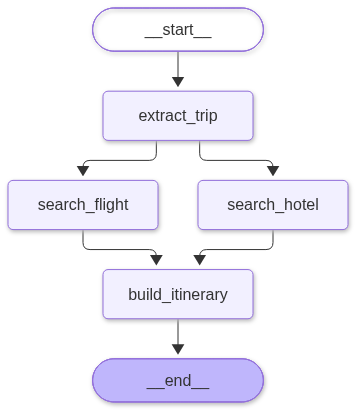

In [ ]:
# graph = travel_graph.compile()
from langgraph.checkpoint.memory import MemorySaver

graph = travel_graph.compile(checkpointer=MemorySaver())
graph

In [ ]:
config = {
    "configurable": {
        "thread_id": "Hello_worls124"
    }
}

user_input = "suggest a 5 day trip iteneary from uk to india"
result = graph.invoke(
    {
        "messages": [HumanMessage(content=user_input)],
        "user_query": user_input,
        "llm_calls": 0,
    },
    config={"configurable": {"thread_id": "test-1"}},
)
print(result["iternary"])

Extract Trip node ::
from_iata='LGW' to_iata='BOM' destination_name='London, UK' departure_date=None
Search Flight node ::
Flight Tool called :: LGW BOM 2026-11-25
Search Hotel node ::
LGW -> BOM 200
LHR -> BOM 200
Build Itinerary node ::
What an exciting trip you're planning from London to India! I've curated a 5-day itinerary for you, incorporating some of the best budget-friendly hotels in London and incorporating the Natural History Museum, which is a must-visit attraction in London.

**Day 1: Arrival and Exploring Shoreditch**

* Arrive at Heathrow Airport and take a taxi or the Tube to your hotel, One Hundred Shoreditch ( approx. £6-8)
* Check-in and freshen up
* Visit the nearby Shoreditch High Street station and explore the trendy neighborhood
* Grab a bite at one of the local eateries or food trucks
* Spend the evening exploring the street art scene and enjoy a drink at a local bar

**Day 2: Natural History Museum and Camden Market**

* Visit the Natural History Museum (free a

In [ ]:
# final_answer

result.get("llm_calls", 0)

5

In [ ]:
"I'd be delighted to help you plan an unforgettable holiday from Gatwick, UK to Malaysia!\n\nConsidering your preferences for affordability, great sightseeing, and ease of following, I've crafted a 10-day itinerary for you:\n\n**Day 1: Arrival in Kuala Lumpur**\n\n* Arrive at Kuala Lumpur International Airport (KLIA) via a direct flight from Gatwick\n* Transfer to your hotel: **Ibis Kuala Lumpur City Centre** ( approx. £25 per night)\n\t+ This 3-star hotel is conveniently located near the Petronas Twin Towers and offers comfortable rooms with modern amenities\n\n**Day 2: Explore KL**\n\n* Visit the iconic **Petronas Twin Towers** (free entry, but book a guided tour for £15-20 per person)\n* Walk to the nearby **Batu Caves**, a series of limestone caves housing Hindu temples and shrines\n* Enjoy a traditional Malaysian street food dinner at **Jalan Alor** (approx. £5-10 per meal)\n\n**Day 3: Batu Caves and Bukit Bintang**\n\n* Visit the **Batu Caves Temple**, one of the largest Hindu temples in Malaysia (free entry)\n* Explore the vibrant shopping and entertainment district of **Bukit Bintang**\n* Enjoy a night out at **KLCC Park**, which offers stunning city views and outdoor activities\n\n**Day 4: Day Trip to Genting Highlands**\n\n* Take a day trip to the **Genting Highlands**, a popular resort town with scenic views, theme parks, and casinos (approx. £20-30 per person, including transportation)\n\t+ Visit the **Genting SkyWorlds** theme park for thrilling rides and attractions\n* Return to KL in the evening\n\n**Day 5: Day Trip to Melaka**\n\n* Take a day trip to the historic city of **Melaka**, a UNESCO World Heritage Site (approx. £20-30 per person, including transportation)\n\t+ Visit the **Melaka Sultanate Palace**, **A.F. Tham** Museum, and **St. Paul's Church**\n\t+ Try some delicious street food at **Jalan Hang Jebat**\n\n**Day 6: Relaxation Day in KL**\n\n* Spend a relaxing day at your hotel or explore nearby attractions\n* Consider visiting the **KLCC Park** again for its scenic views and outdoor activities\n\n**Day 7: Cultural Experience in KL**\n\n* Visit the **National Museum**, which showcases Malaysia's rich history and culture (free entry)\n* Explore the trendy **Bukit Mewah** neighborhood, known for its street art, cafes, and boutique shops\n* Enjoy a traditional Malay dinner at **Taman Connaught**\n\n**Day 8: Day Trip to Taman Negara National Park**\n\n* Take a day trip to the **Taman Negara National Park**, one of the oldest rainforests in the world (approx. £30-40 per person, including transportation)\n\t+ Go on a guided jungle trek and spot exotic wildlife\n\n**Day 9: Last Day in KL**\n\n* Spend your last day in KL exploring nearby attractions or doing some last-minute shopping\n* Consider visiting the **Kuala Lumpur Tower**, which offers panoramic views of the city (approx. £10-15 per person)\n\n**Day 10: Departure from KL**\n\n* Return to Gatwick via a direct flight\n\n**Budget Breakdown:**\n\n* Flights from Gatwick to KLIA: approx. £500-600 return\n* Accommodation for 9 nights: approx. £200-250 (Ibis Kuala Lumpur City Centre)\n* Transportation and activities: approx. £300-400 per person\n* Food and miscellaneous expenses: approx. £200-300 per person\n\nTotal estimated cost for the 10-day itinerary: approx. £1,500-2,000 per person\n\nThis budget-friendly itinerary offers a mix of culture, history, and adventure, while also providing comfort and convenience. I hope you enjoy your trip to Malaysia!"

In [44]:
from travel_agent.travel_agent.tools import search_oag

In [ ]:
import sys; sys.path.insert(0, "/Users/omkar/Documents/supplychain")

In [13]:
import os

BASE_PATH = os.path.join("/Users/omkar/Documents/supplychain")
agent_path = BASE_PATH.join("travel_agent")
agent_path

't/Users/omkar/Documents/supplychainr/Users/omkar/Documents/supplychaina/Users/omkar/Documents/supplychainv/Users/omkar/Documents/supplychaine/Users/omkar/Documents/supplychainl/Users/omkar/Documents/supplychain_/Users/omkar/Documents/supplychaina/Users/omkar/Documents/supplychaing/Users/omkar/Documents/supplychaine/Users/omkar/Documents/supplychainn/Users/omkar/Documents/supplychaint'